<h1 align = "Center">
Lotus Group Customer Value & Profitability Analysis

<h2 align = "Center">
Machine Learning Part B — Detecting Loss-Making Orders
</h2>
</h1>

**Research question 4:** *Which combinations of basket and discount lead to loss-making orders?*

We train a **decision tree classifier** that looks at an order at checkout (what is in the basket and which discounts were applied) and flags it if it is likely to **lose money**. A decision tree is chosen deliberately: it can be read as a short set of rules that a store manager or a pricing system can apply without any software.

Success criteria, set in the project charter **before** modelling:

| Criterion | Target |
|---|---|
| Recall on loss-making orders in 2024 | ≥ 90% of loss-making orders caught |
| Comparison with a simple rule | Outperforms the "discount ≥ 25%" rule |
| Interpretability | Tree depth ≤ 5, so it reads as rules |
| Validation | Chronological: train on 2022–2023, test once on 2024 |

**Why recall comes first:** a missed loss-making order costs real money, while a false alarm only means a manager double-checks a discount. We still track **precision** (how many flagged orders really lose money), so the check doesn't flag so many orders that staff start ignoring it.

# Setup and Data Loading

In [1]:
import pandas as pd
from pathlib import Path

features_path = Path("../01_Data/features")
outputs_path = Path("../01_Data/outputs")
models_path = Path("../06_Models")
images_path = Path("../05_Images")
for folder in (outputs_path, models_path, images_path):
    folder.mkdir(parents=True, exist_ok=True)

orders = pd.read_csv(features_path / "order_features.csv", parse_dates=["order_date"])

RANDOM_STATE = 42

print("Orders:", orders.shape)
orders.groupby("order_year").agg(
    orders=("order_id", "size"),
    loss_making=("loss_making", "sum"),
    loss_rate=("loss_making", "mean"),
).style.format({"loss_rate": "{:.2%}"})

Orders: (10529, 24)

,orders,loss_making,loss_rate
order_year,,,
2022,3463,54,1.56%
2023,3530,32,0.91%
2024,3536,40,1.13%


Only about **1.2% of orders lose money** in every year. With so few positives, accuracy would be meaningless: a model that never flags anything would be 98.8% accurate and completely useless. We therefore judge models on **recall**, **precision** and **F1** (the balance of the two).

### Chart style

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

NAVY = "#00274B"
ELECTRONICS = "#2B79B8"
LOSS = "#C2410C"
MUTED = "#6B7280"
percent = FuncFormatter(lambda v, _: f"{v:.0%}")

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#a3a29c",
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "lines.linewidth": 2,
})

# Features and Data Split

### Which features?

The feature engineering notebook prepared two kinds of checkout information:

- **Basket and discount features**: size, value, product mix and discounts.
- **Context features**: store type, payment method, loyalty tier and month.

The exploratory analysis found that every loss-making order contained an Electronics item at 20% off or more. Store margins were all alike, and there was no seasonal pattern. We therefore expect the basket and discount features to carry the signal. We test whether the context features add anything before deciding to leave them out.

Cost and profit are **never** used as features. They define the target only.

In [3]:
basket_features = [
    "lines", "items", "electronics_items", "clothing_items",
    "list_value", "order_value", "electronics_value_share",
    "max_discount", "max_electronics_discount", "average_discount",
    "electronics_value_at_20pct_plus",
]
context_features = ["store_type", "payment_method", "loyalty_tier", "order_month"]

target = "loss_making"

### Chronological split

To choose the model fairly, we hold back one more period:

| Set | Orders from | Purpose |
|---|---|---|
| Fit | 2022 | Fit candidate trees |
| Validation | 2023 | Choose tree settings and the flagging threshold |
| **Test** | **2024** | **Final, one-time evaluation** |

Once the settings are chosen, the final tree is refitted on all of 2022–2023 (the charter's training period) and evaluated once on 2024.

In [4]:
fit_mask = orders["order_year"] == 2022
valid_mask = orders["order_year"] == 2023
train_mask = orders["dataset"] == "train"   # 2022–2023
test_mask = orders["dataset"] == "test"     # 2024

y = orders[target]
for name, mask in [("Fit (2022)", fit_mask), ("Validation (2023)", valid_mask),
                   ("Train (2022–2023)", train_mask), ("Test (2024)", test_mask)]:
    print(f"{name:20s} orders: {mask.sum():>5,}   loss-making: {y[mask].sum():>3}")

Fit (2022)           orders: 3,463   loss-making:  54
Validation (2023)    orders: 3,530   loss-making:  32
Train (2022–2023)    orders: 6,993   loss-making:  86
Test (2024)          orders: 3,536   loss-making:  40

# Baseline Rules

A model is only worth using if it beats simple rules a manager could apply without it. We compare against three:

| Rule | Flag the order if… |
|---|---|
| **Charter rule** | any item is discounted 25% or more |
| Electronics ≥ 25% | an **Electronics** item is discounted 25% or more |
| Electronics ≥ 20% | an **Electronics** item is discounted 20% or more |

The second and third rules use what we learned in the exploratory analysis, so they are tougher benchmarks than the charter rule.

In [5]:
from sklearn.metrics import recall_score, precision_score, f1_score

def evaluate(name, y_true, flagged):
    return {
        "approach": name,
        "recall": recall_score(y_true, flagged),
        "precision": precision_score(y_true, flagged, zero_division=0),
        "F1": f1_score(y_true, flagged),
        "orders flagged": int(flagged.sum()),
        "loss-making caught": int((flagged & (y_true == 1)).sum()),
        "loss-making missed": int((~flagged & (y_true == 1)).sum()),
    }

rules = {
    "Charter rule: any discount ≥ 25%": lambda d: d["max_discount"] >= 25,
    "Rule: Electronics discount ≥ 25%": lambda d: d["max_electronics_discount"] >= 25,
    "Rule: Electronics discount ≥ 20%": lambda d: d["max_electronics_discount"] >= 20,
}

pd.DataFrame([
    evaluate(name, y[valid_mask], rule(orders[valid_mask]).to_numpy())
    for name, rule in rules.items()
]).set_index("approach").style.format(
    {"recall": "{:.1%}", "precision": "{:.1%}", "F1": "{:.3f}"}
)

,recall,precision,F1,orders flagged,loss-making caught,loss-making missed
approach,,,,,,
Charter rule: any discount ≥ 25%,87.5%,5.8%,0.109,484,28,4
Rule: Electronics discount ≥ 25%,87.5%,59.6%,0.709,47,28,4
Rule: Electronics discount ≥ 20%,100.0%,30.2%,0.464,106,32,0


On the 2023 validation data:

- The **charter rule** catches most losses but is buried in false alarms. Clothing can safely be discounted 25%, so most of its flags are wrong.
- **Electronics ≥ 20%** catches everything, but flags more than two safe orders for every loss-making one.
- **Electronics ≥ 25%** has the best balance, but it misses every loss at exactly 20% off.

The model's job is to keep recall at or above 90% while flagging fewer safe orders than these rules.

# Choosing the Tree

We try every combination of:

- **Maximum depth** 2–5 (the charter's limit for readability).
- **Minimum orders per leaf** of 5, 10, 20 or 40. Larger leaves give more general rules that are less likely to memorise individual orders.

A decision tree outputs a **probability** that an order loses money. The usual cut-off of 0.5 is not necessarily right when losses are this rare, so for each tree we also choose the **flagging threshold**.

**Recall safety margin.** The 2023 validation year has only **32** loss-making orders, so each one moves recall by about 3 percentage points. A tree that only just reaches 90% on validation can easily fall below 90% on new data. We therefore require **at least 95% recall on validation**, a margin above the 90% target, and among the trees that achieve it, we pick the one with the best F1.

> *Transparency note:* an earlier version of this notebook required only 90% recall on validation. The tree it selected caught 87.5% of 2024 losses, below target. That showed the margin was needed, and the rule was tightened to 95%.

In [6]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

MIN_VALIDATION_RECALL = 0.95

def tune_tree(feature_columns, X_fit, X_valid):
    results = []
    for depth in (2, 3, 4, 5):
        for min_leaf in (5, 10, 20, 40):
            tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=min_leaf,
                                          random_state=RANDOM_STATE)
            tree.fit(X_fit, y[fit_mask])
            scores = tree.predict_proba(X_valid)[:, 1]
            for threshold in np.unique(scores[scores > 0]):
                flagged = scores >= threshold
                recall = recall_score(y[valid_mask], flagged)
                if recall >= MIN_VALIDATION_RECALL:
                    results.append({
                        "max_depth": depth, "min_samples_leaf": min_leaf,
                        "threshold": threshold, "recall": recall,
                        "precision": precision_score(y[valid_mask], flagged),
                        "F1": f1_score(y[valid_mask], flagged),
                    })
    return (pd.DataFrame(results)
            .sort_values(["F1", "max_depth", "min_samples_leaf"], ascending=[False, True, False])
            .reset_index(drop=True))

basket_results = tune_tree(basket_features, orders.loc[fit_mask, basket_features],
                           orders.loc[valid_mask, basket_features])
basket_results.head(5).style.format(
    {"threshold": "{:.2f}", "recall": "{:.1%}", "precision": "{:.1%}", "F1": "{:.3f}"}
)

,max_depth,min_samples_leaf,threshold,recall,precision,F1
0,3,20,0.40,96.9%,66.0%,0.785
1,4,20,0.40,96.9%,66.0%,0.785
2,5,20,0.40,96.9%,66.0%,0.785
3,3,10,0.62,96.9%,63.3%,0.765
4,3,5,0.40,96.9%,63.3%,0.765


### Do the context features help?

We repeat the search with store type, payment method, loyalty tier and month added. These are one-hot encoded: each category becomes a yes/no column.

In [7]:
with_context = pd.get_dummies(
    orders[basket_features + context_features],
    columns=["store_type", "payment_method", "loyalty_tier"], dtype=float,
)
context_results = tune_tree(list(with_context.columns),
                            with_context[fit_mask], with_context[valid_mask])

pd.DataFrame({
    "best validation F1": [basket_results.loc[0, "F1"], context_results.loc[0, "F1"]],
    "precision": [basket_results.loc[0, "precision"], context_results.loc[0, "precision"]],
    "recall": [basket_results.loc[0, "recall"], context_results.loc[0, "recall"]],
}, index=["Basket and discount features", "Plus context features"]).style.format(
    {"best validation F1": "{:.3f}", "precision": "{:.1%}", "recall": "{:.1%}"}
)

,best validation F1,precision,recall
Basket and discount features,0.785,66.0%,96.9%
Plus context features,0.805,68.9%,96.9%


The context features give a **small improvement** on validation. Before accepting it, we look at *where* the improvement comes from: which context features the best tree actually uses.

In [8]:
best_context = context_results.iloc[0]
context_tree = DecisionTreeClassifier(
    max_depth=int(best_context["max_depth"]),
    min_samples_leaf=int(best_context["min_samples_leaf"]),
    random_state=RANDOM_STATE,
).fit(with_context[fit_mask], y[fit_mask])

used = pd.Series(context_tree.feature_importances_, index=with_context.columns)
used[used > 0].sort_values(ascending=False).round(3)

max_electronics_discount           0.640
average_discount                   0.276
electronics_value_at_20pct_plus    0.033
electronics_value_share            0.033
order_month                        0.018

The only context feature the tree uses is **`order_month`**. It splits large all-Electronics baskets into "January–October" and "November–December" orders. The exploratory analysis found **no seasonal pattern** in revenue or margin, and there's no business reason why the same discount on the same basket should lose money in October but not in November. The split is fitting chance variation in 2022, not a real rule.

We therefore keep the model with **basket and discount features only**. It is easier to explain, and every rule in it has a clear business reason.

### Selected settings

In [9]:
best = basket_results.iloc[0]
BEST_DEPTH = int(best["max_depth"])
BEST_MIN_LEAF = int(best["min_samples_leaf"])
THRESHOLD = float(best["threshold"])

print(f"Maximum depth:          {BEST_DEPTH}")
print(f"Minimum orders per leaf: {BEST_MIN_LEAF}")
print(f"Flagging threshold:     {THRESHOLD:.2f}")
print(f"Validation recall {best['recall']:.1%}, precision {best['precision']:.1%}, F1 {best['F1']:.3f}")

Maximum depth:          3
Minimum orders per leaf: 20
Flagging threshold:     0.40
Validation recall 96.9%, precision 66.0%, F1 0.785

Several deeper trees tie with this one on validation, and we prefer the **shallowest**: it gives the same performance with fewer, simpler rules.

# Final Model and Test Results

We refit the chosen tree on all 2022–2023 orders and apply it **once** to the 2024 orders it has never seen.

In [10]:
X_train = orders.loc[train_mask, basket_features]
X_test = orders.loc[test_mask, basket_features]
y_train, y_test = y[train_mask], y[test_mask]

final_tree = DecisionTreeClassifier(
    max_depth=BEST_DEPTH, min_samples_leaf=BEST_MIN_LEAF, random_state=RANDOM_STATE
)
final_tree.fit(X_train, y_train)

test_scores = final_tree.predict_proba(X_test)[:, 1]
test_flagged = test_scores >= THRESHOLD

test_results = pd.DataFrame(
    [evaluate(name, y_test, rule(orders[test_mask]).to_numpy()) for name, rule in rules.items()]
    + [evaluate("Decision tree", y_test, test_flagged)]
).set_index("approach")

test_results.style.format(
    {"recall": "{:.1%}", "precision": "{:.1%}", "F1": "{:.3f}"}
).highlight_max(subset=["F1"], color="#d8ecd9")

,recall,precision,F1,orders flagged,loss-making caught,loss-making missed
approach,,,,,,
Charter rule: any discount ≥ 25%,92.5%,7.8%,0.145,472,37,3
Rule: Electronics discount ≥ 25%,92.5%,67.3%,0.779,55,37,3
Rule: Electronics discount ≥ 20%,100.0%,37.4%,0.544,107,40,0
Decision tree,95.0%,74.5%,0.835,51,38,2


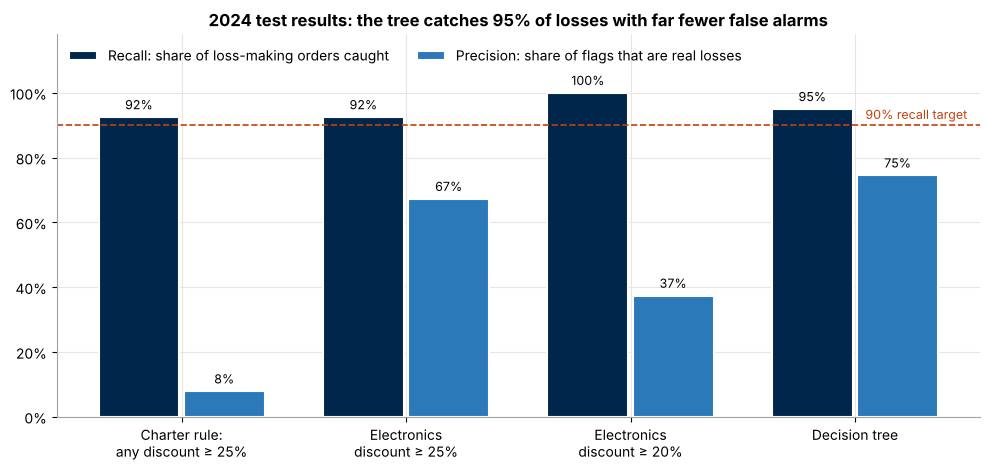

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.8))
labels = ["Charter rule:\nany discount ≥ 25%", "Electronics\ndiscount ≥ 25%",
          "Electronics\ndiscount ≥ 20%", "Decision tree"]
x = np.arange(len(labels))
width = 0.36
recall_bars = ax.bar(x - width / 2 - 0.01, test_results["recall"], width, color=NAVY,
                     label="Recall: share of loss-making orders caught", edgecolor="white", linewidth=1.5)
precision_bars = ax.bar(x + width / 2 + 0.01, test_results["precision"], width, color=ELECTRONICS,
                        label="Precision: share of flags that are real losses", edgecolor="white", linewidth=1.5)
for bars in (recall_bars, precision_bars):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                f"{bar.get_height():.0%}", ha="center", va="bottom", fontsize=9)
ax.axhline(0.90, color=LOSS, linestyle="--", linewidth=1.2)
ax.text(len(labels) - 0.5, 0.91, "90% recall target", color=LOSS, ha="right", va="bottom", fontsize=9)
ax.set_xticks(x, labels)
ax.yaxis.set_major_formatter(percent)
ax.set_ylim(0, 1.18)
ax.set_title("2024 test results: the tree catches 95% of losses with far fewer false alarms")
ax.legend(frameon=False, loc="upper left", ncol=2)
plt.tight_layout()
plt.savefig(images_path / "loss_model_vs_rules.png", dpi=150, bbox_inches="tight")
plt.show()

**On unseen 2024 orders, the decision tree:**

- **Catches 95% of loss-making orders** (38 of 40), above the 90% target.
- **Is right 3 times out of 4 when it flags an order** (precision ~75%), against **8%** for the charter rule and **37%** for the "Electronics ≥ 20%" rule.
- Has the **best F1 of all approaches**, ahead of the toughest benchmark, "Electronics ≥ 25%", which misses losses at 20% off.

### Confusion matrix

In [12]:
from sklearn.metrics import confusion_matrix

pd.DataFrame(
    confusion_matrix(y_test, test_flagged),
    index=["Actual: profitable", "Actual: loss-making"],
    columns=["Not flagged", "Flagged"],
)

,Not flagged,Flagged
Actual: profitable,3483,13
Actual: loss-making,2,38


Out of **3,536** orders in 2024, the tree flags about **50** for review. Fewer than 1 order in 70 would need a second look, which is a realistic workload for store managers.

## How much money does it protect?

In [13]:
test_orders = orders[test_mask].assign(flagged=test_flagged)
losses = test_orders[test_orders["loss_making"] == 1]

caught_loss = losses.loc[losses["flagged"], "order_profit"].sum()
missed_loss = losses.loc[~losses["flagged"], "order_profit"].sum()
print(f"Losses on flagged orders: EGP {-caught_loss:,.0f}")
print(f"Losses on missed orders:  EGP {-missed_loss:,.0f}")
print(f"Share of loss value caught: {caught_loss / (caught_loss + missed_loss):.1%}")

false_alarms = test_orders[test_orders["flagged"] & (test_orders["loss_making"] == 0)]
print(f"\nFalse alarms: {len(false_alarms)} orders, median profit EGP {false_alarms['order_profit'].median():,.0f}")

Losses on flagged orders: EGP 40,440
Losses on missed orders:  EGP 518
Share of loss value caught: 98.7%

False alarms: 13 orders, median profit EGP 240

- The two missed orders lost only about **EGP 500** between them. In money terms, the tree catches **almost 99% of the value lost** to loss-making orders in 2024.
- The false alarms are orders that **barely made a profit** (a median of a few hundred EGP). Reviewing them is not wasted effort, because they are discounted down to almost no margin.

### Benchmark: how much accuracy does readability cost?

Gradient boosting combines hundreds of trees and is usually more accurate, but it can't be read as rules. We compare it on **average precision**, a threshold-free score of how well each model ranks risky orders above safe ones.

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

boosting = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
boosting_scores = boosting.predict_proba(X_test)[:, 1]

pd.DataFrame({
    "average precision (2024)": [
        average_precision_score(y_test, test_scores),
        average_precision_score(y_test, boosting_scores),
    ],
    "readable as rules": ["Yes", "No"],
}, index=["Decision tree (depth 3)", "Gradient boosting"]).style.format(
    {"average precision (2024)": "{:.3f}"}
)

,average precision (2024),readable as rules
Decision tree (depth 3),0.845,Yes
Gradient boosting,0.989,No


Gradient boosting **ranks orders clearly better** (0.99 vs 0.85). This is expected: the depth-3 tree gives only a handful of distinct risk levels, one per leaf, so it can't finely order orders within a leaf.

For the job we need, however, which is a **yes/no approval rule**, what matters is performance at the chosen threshold. There, the tree already meets the recall target with good precision, and it can be printed on one page and followed by store managers and auditors. The boosting model is a good candidate for a later phase, if Lotus Group wants an automated risk score built into its point-of-sale system.

# From Model to Business Rules

## The tree

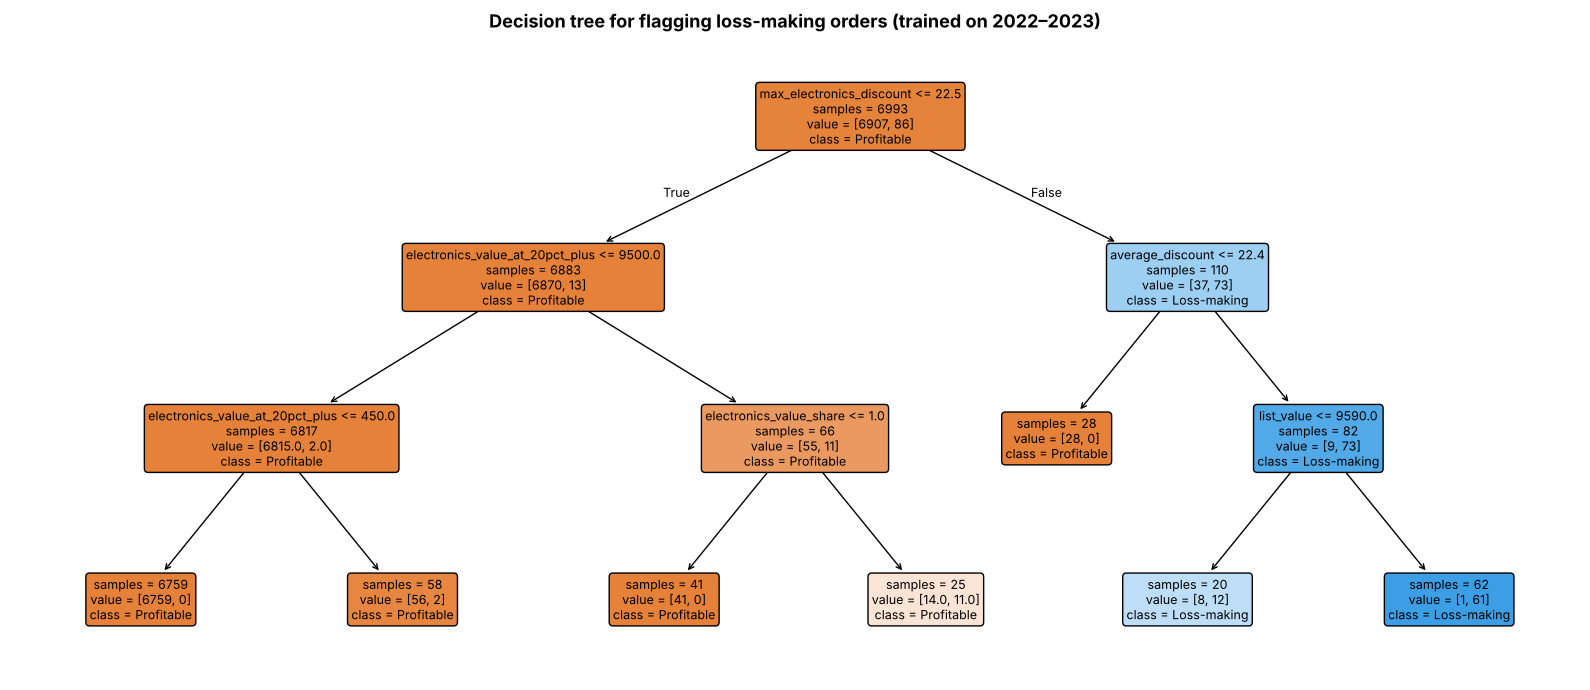

In [15]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    final_tree,
    feature_names=basket_features,
    class_names=["Profitable", "Loss-making"],
    filled=True, rounded=True, impurity=False, proportion=False,
    precision=1, fontsize=9, ax=ax,
)
ax.set_title("Decision tree for flagging loss-making orders (trained on 2022–2023)", fontsize=13)
plt.tight_layout()
plt.savefig(images_path / "loss_rules_tree.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
from sklearn.tree import export_text

print(export_text(final_tree, feature_names=basket_features, show_weights=True, decimals=2))

|--- max_electronics_discount <= 22.50
|   |--- electronics_value_at_20pct_plus <= 9500.00
|   |   |--- electronics_value_at_20pct_plus <= 450.00
|   |   |   |--- weights: [6759.00, 0.00] class: 0
|   |   |--- electronics_value_at_20pct_plus >  450.00
|   |   |   |--- weights: [56.00, 2.00] class: 0
|   |--- electronics_value_at_20pct_plus >  9500.00
|   |   |--- electronics_value_share <= 1.00
|   |   |   |--- weights: [41.00, 0.00] class: 0
|   |   |--- electronics_value_share >  1.00
|   |   |   |--- weights: [14.00, 11.00] class: 0
|--- max_electronics_discount >  22.50
|   |--- average_discount <= 22.41
|   |   |--- weights: [28.00, 0.00] class: 0
|   |--- average_discount >  22.41
|   |   |--- list_value <= 9590.00
|   |   |   |--- weights: [8.00, 12.00] class: 1
|   |   |--- list_value >  9590.00
|   |   |   |--- weights: [1.00, 61.00] class: 1

In each leaf, `weights: [profitable, loss-making]` shows how many 2022–2023 orders ended up there. The `class` label and colour in the chart show each leaf's *majority*. Our model instead flags a leaf when its share of loss-making orders is at or above the chosen **threshold of 0.40**. That is why a leaf with 11 losses out of 25 orders (44%) is flagged even though most of its orders were profitable.

## The rules in plain language

To turn the tree into rules, we list every leaf that gets flagged, with its share of loss-making orders and how many training orders it covers.

In [17]:
leaf_ids = final_tree.apply(X_train)
leaf_summary = (
    pd.DataFrame({"leaf": leaf_ids, "loss_making": y_train.to_numpy()})
    .groupby("leaf")
    .agg(orders=("loss_making", "size"), loss_making=("loss_making", "sum"))
)
leaf_summary["loss_rate"] = leaf_summary["loss_making"] / leaf_summary["orders"]
leaf_summary["flagged"] = leaf_summary["loss_rate"] >= THRESHOLD

leaf_summary.sort_values("loss_rate", ascending=False).style.format({"loss_rate": "{:.0%}"})

,orders,loss_making,loss_rate,flagged
leaf,,,,
12,62,61,98%,True
11,20,12,60%,True
7,25,11,44%,True
4,58,2,3%,False
3,6759,0,0%,False
6,41,0,0%,False
9,28,0,0%,False


Reading the flagged leaves from the tree above, the model reduces to **three checkout rules**. *Discounts in Lotus Group's data come in 5% steps, so "above 22.5%" means 25% or 30%.*

> **Ask for manager approval before completing an order if:**
>
> 1. **An Electronics item is discounted 25% or more, and the basket's overall discount is above about 22%, on a basket worth more than about EGP 9,600 before discounts.** This is almost always a loss.
> 2. **An Electronics item is discounted 25% or more, and the basket's overall discount is above about 22%, on a smaller basket.** This loses money more often than not.
> 3. **The basket is entirely Electronics, with at least EGP 9,500 of Electronics sold at 20% off.** This loses money almost half the time, depending on the products' margins.
>
> **No approval needed:** baskets where a deep Electronics discount is diluted by full-price items (overall discount below ~22%), any basket whose Electronics discounts are 15% or less, and all Clothing-only baskets.

The rules match the economics found in the exploratory analysis. Electronics carry a margin of only 12.5–33%, so a 25–30% discount pushes them below cost unless other full-price items in the basket make up the difference.

## Which features matter most?

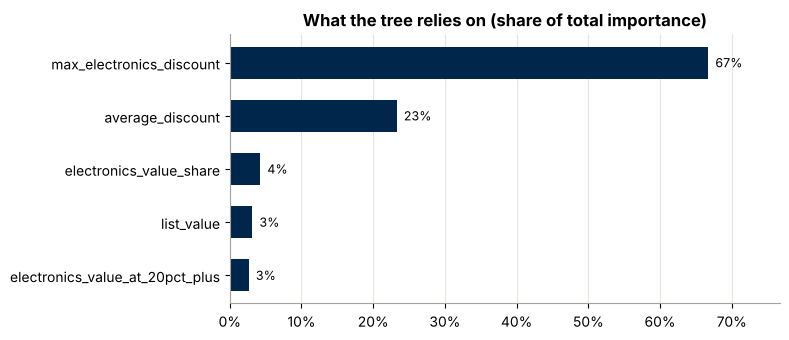

In [18]:
importance = (
    pd.Series(final_tree.feature_importances_, index=basket_features)
    .sort_values(ascending=True)
    .loc[lambda s: s > 0]
)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(importance.index, importance.values, color=NAVY, height=0.6)
for i, v in enumerate(importance.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
ax.xaxis.set_major_formatter(percent)
ax.set_xlim(0, importance.max() * 1.15)
ax.set_title("What the tree relies on (share of total importance)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

The **highest Electronics discount** in the basket does most of the work. The **overall basket discount** comes second, because it separates baskets where full-price items rescue the deep discount from those where they don't.

# Success Criteria Check

In [19]:
tree_test = test_results.loc["Decision tree"]
charter_rule = test_results.loc["Charter rule: any discount ≥ 25%"]
best_rule_f1 = test_results.drop(index="Decision tree")["F1"].max()

criteria = pd.DataFrame([
    ("Recall on 2024 loss-making orders", "≥ 90%", f"{tree_test['recall']:.0%}", tree_test["recall"] >= 0.90),
    ("Beats the charter rule (any discount ≥ 25%)", "Higher F1",
     f"F1 {tree_test['F1']:.2f} vs {charter_rule['F1']:.2f}", tree_test["F1"] > charter_rule["F1"]),
    ("Beats every baseline rule", "Higher F1",
     f"F1 {tree_test['F1']:.2f} vs best rule {best_rule_f1:.2f}", tree_test["F1"] > best_rule_f1),
    ("Readable as rules", "Depth ≤ 5", f"Depth {final_tree.get_depth()}", final_tree.get_depth() <= 5),
    ("Chronological validation", "Train 2022–23, test 2024", "Yes", True),
], columns=["criterion", "target", "result", "met"])
criteria["met"] = criteria["met"].map({True: "✅ Yes", False: "❌ No"})
criteria.set_index("criterion")

,target,result,met
criterion,,,
Recall on 2024 loss-making orders,≥ 90%,95%,✅ Yes
Beats the charter rule (any discount ≥ 25%),Higher F1,F1 0.84 vs 0.14,✅ Yes
Beats every baseline rule,Higher F1,F1 0.84 vs best rule 0.78,✅ Yes
Readable as rules,Depth ≤ 5,Depth 3,✅ Yes
Chronological validation,"Train 2022–23, test 2024",Yes,✅ Yes


**All success criteria are met.**

A caveat on the size of the evidence: the 2024 test set contains **40 loss-making orders**, so each one moves recall by 2.5 percentage points. The result is consistent across the validation year (2023) and the test year (2024), which gives confidence that the rules are not a fluke of one period.

# Saving the Model and Flags

In [20]:
import joblib

joblib.dump(
    {"model": final_tree, "features": basket_features, "threshold": THRESHOLD},
    models_path / "loss_order_tree.joblib",
)

flags_2024 = test_orders[[
    "order_id", "order_date", "store_id", "order_value", "max_electronics_discount",
    "average_discount", "order_profit", "loss_making", "flagged",
]].assign(loss_risk=test_scores)
flags_2024.to_csv(outputs_path / "order_risk_flags_2024.csv", index=False)

print("Saved model: 06_Models/loss_order_tree.joblib")
print("Saved 2024 flags:", flags_2024.shape)

Saved model: 06_Models/loss_order_tree.joblib
Saved 2024 flags: (3536, 10)

# Summary

| | |
|---|---|
| **Method** | Decision tree (depth 3) on basket and discount features known at checkout; threshold chosen on 2023, tested once on 2024 |
| **Result** | Catches **95% of loss-making orders** (38 of 40) and **~99% of the money lost**, while flagging only ~1 in 70 orders |
| **Versus simple rules** | Precision **~75%**, vs 8% for "any discount ≥ 25%" and 37% for "Electronics ≥ 20%"; best F1 of every approach |
| **Business rules** | Ask for approval when an Electronics item is discounted 25%+ and the basket's overall discount stays above ~22%, or when an all-Electronics basket has ≥ EGP 9,500 at 20% off |

**Outputs:** `06_Models/loss_order_tree.joblib`, `01_Data/outputs/order_risk_flags_2024.csv`, `05_Images/loss_model_vs_rules.png` and `05_Images/loss_rules_tree.png`.

**Next step:** estimate how much profit discount limits would have protected, and turn both models into recommendations.